In [17]:
import pandas as pd 
from pathlib import Path
import matplotlib.pyplot as plt

In [18]:
Path.cwd().parent 

PosixPath('/Users/bluk/Developer/github-best-pratices/alert_analysis')

In [36]:
df = pd.read_json(
    Path.cwd().parent / "analyzed_original.json"
)
df["hierarchy"] = df["file"].str.removeprefix("/workspaces/github-best-pratices/extraction/gh-docs-2026-02-19/content")
df["topic"] = df["hierarchy"].map(lambda x: Path(x).parts[1])

files_df = df[["hierarchy", "words"]].copy()
highlights_df = (
    df
    .explode("highlight")                     # one row per highlight
    .dropna(subset=["highlight"])             # remove empty ones
    .reset_index(drop=True)
)
highlights_expanded = pd.json_normalize(highlights_df["highlight"])
highlights_df = pd.concat(
    [highlights_df.drop(columns=["highlight"]), highlights_expanded],
    axis=1
)

In [37]:
files_df

,hierarchy,words
0,/organizations/managing-peoples-access-to-your...,1910
1,/organizations/managing-peoples-access-to-your...,4827
2,/organizations/managing-peoples-access-to-your...,611
3,/organizations/managing-peoples-access-to-your...,1117
4,/organizations/managing-peoples-access-to-your...,454
...,...,...
2848,/code-security/concepts/secret-security/workin...,237
2849,/code-security/concepts/secret-security/about-...,805
2850,/code-security/concepts/secret-security/push-p...,371
2851,/code-security/concepts/secret-security/about-...,403


In [38]:
highlights_df

,file,words,hierarchy,topic,type,content
0,/workspaces/github-best-pratices/extraction/gh...,1910,/organizations/managing-peoples-access-to-your...,organizations,note,Adding repository permissions to a custom orga...
1,/workspaces/github-best-pratices/extraction/gh...,1117,/organizations/managing-peoples-access-to-your...,organizations,note,Adding a repository role and permissions to a ...
2,/workspaces/github-best-pratices/extraction/gh...,297,/organizations/managing-peoples-access-to-your...,organizations,note,Organization owners and billing managers can a...
3,/workspaces/github-best-pratices/extraction/gh...,372,/organizations/managing-peoples-access-to-your...,organizations,note,"As an organization owner, you can change the r..."
4,/workspaces/github-best-pratices/extraction/gh...,626,/organizations/managing-peoples-access-to-your...,organizations,note,Billing managers do not use paid licenses in y...
...,...,...,...,...,...,...
3310,/workspaces/github-best-pratices/extraction/gh...,1434,/code-security/concepts/secret-security/about-...,code-security,tip,Regardless of the enablement status of push pr...
3311,/workspaces/github-best-pratices/extraction/gh...,656,/code-security/concepts/secret-security/about-...,code-security,tip,"At any time, you can run a free assessment of ..."
3312,/workspaces/github-best-pratices/extraction/gh...,805,/code-security/concepts/secret-security/about-...,code-security,note,You can also enable push protection for your p...
3313,/workspaces/github-best-pratices/extraction/gh...,371,/code-security/concepts/secret-security/push-p...,code-security,note,* If your Git configuration supports pushes to...


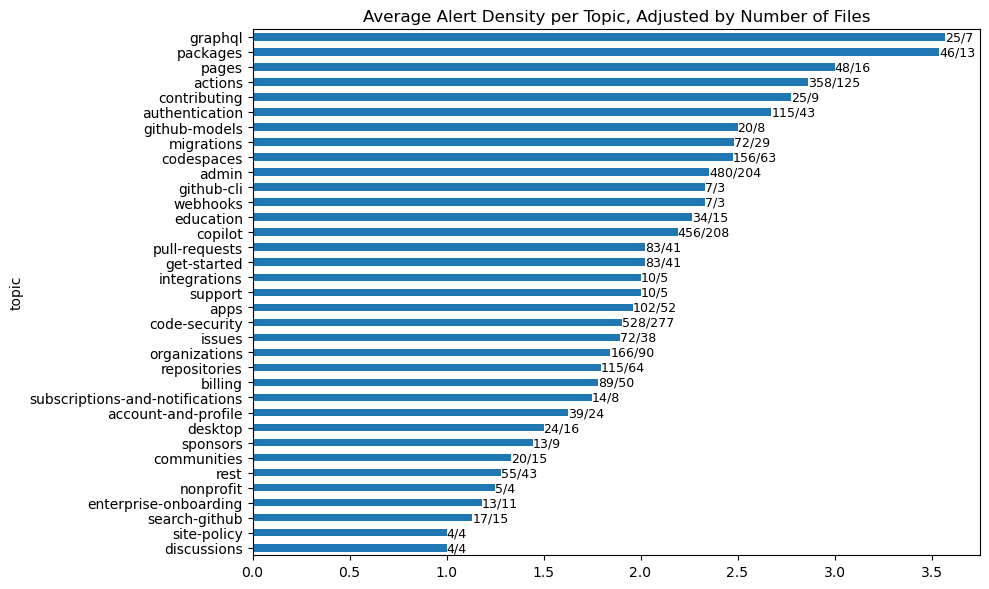

In [39]:
dfall = highlights_df

pages_per_topic = dfall.groupby("topic")["hierarchy"].nunique()
alerts_per_topic = dfall.groupby("topic").size()

averages = (alerts_per_topic / pages_per_topic).sort_values()

ax = averages.plot(
    kind="barh",
    figsize=(10, 6),
    title="Average Alert Density per Topic, Adjusted by Number of Files"
)

# values only used for labels (not plotted)
ratio = pages_per_topic / alerts_per_topic

for bar, topic in zip(ax.patches, averages.index):
    value = ratio.loc[topic]
    ax.text(
        bar.get_width(),                    # x-position (end of bar)
        bar.get_y() + bar.get_height() / 2, # y-position (center)
        f"{alerts_per_topic[topic]}/{pages_per_topic[topic]}",                     # label text
        va="center",
        ha="left",
        fontsize=9
    )

plt.tight_layout()
plt.show()

<Axes: title={'center': 'Distribution of alerts per topic'}, ylabel='topic'>

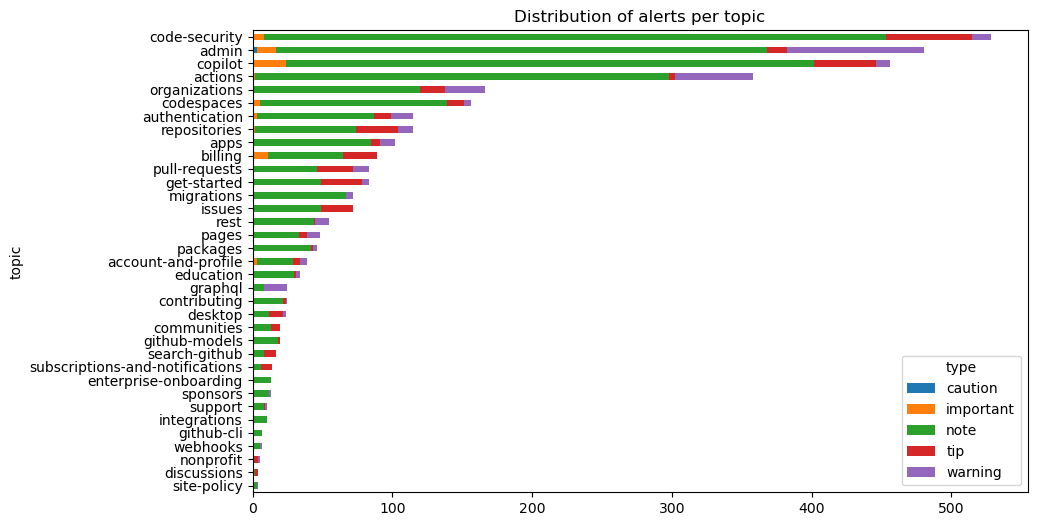

In [40]:
pivot = pd.crosstab(highlights_df["topic"], highlights_df["type"])
pivot = pivot.loc[pivot.sum(axis=1).sort_values().index]
pivot.plot(kind="barh", stacked=True, figsize=(10, 6),title="Distribution of alerts per topic")

In [41]:
highlights_df["type"].value_counts()

type
note         2547
tip           362
warning       325
important      76
caution         5
Name: count, dtype: int64

In [42]:
interesting = [
    "/actions",
    "/packages",
    "/code-security",
    "/code-security/how-tos/secure-your-secrets",
    "/code-security/how-tos/secure-your-supply-chain",
    "/code-security/how-tos/maintain-quality-code",
    "/code-security/how-tos/secure-at-scale",
]

data = []

for prefix in interesting:
    # 1. Filter for rows where the file path starts with the prefix
    df_subset_highlights = highlights_df[highlights_df['hierarchy'].str.startswith(prefix)]
    df_subset_files = files_df[files_df['hierarchy'].str.startswith(prefix)]
    
    # 2. Calculate metrics
    # Note: Using .nunique() assumes you want the count of unique files. 
    # If you just want the raw number of rows, use len(df_subset) instead.
    row = {
        'Prefix': prefix.split("/")[-1],
        'Number of files': df_subset_files['hierarchy'].count(),
        'number of words': round(df_subset_files["words"].sum() / df_subset_files['hierarchy'].count(),2),
        'caution': (df_subset_highlights['type'] == 'caution').sum(),
        'important': (df_subset_highlights['type'] == 'important').sum(),
        'warning': (df_subset_highlights['type'] == 'warning').sum()
    }
    
    data.append(row)

data.append(
    {
        'Prefix': "/",
        'Number of files': files_df['hierarchy'].nunique(),
        'number of words': files_df["words"].sum() / files_df['hierarchy'].nunique(),
        'caution': (highlights_df['type'] == 'caution').sum(),
        'important': (highlights_df['type'] == 'important').sum(),
        'warning': (highlights_df['type'] == 'warning').sum()
    }
)


# 3. Create the new DataFrame
summary_df = pd.DataFrame(data)
summary_df.set_index('Prefix', inplace=True)
summary_df

,Number of files,number of words,caution,important,warning
Prefix,,,,,
actions,200,1384.620000,0,2,56
packages,20,1370.750000,0,0,3
code-security,419,1186.110000,0,8,13
secure-your-secrets,16,953.000000,0,0,0
secure-your-supply-chain,33,1096.390000,0,0,1
maintain-quality-code,4,615.500000,0,0,0
secure-at-scale,40,785.250000,0,2,6
/,2853,1660.070452,5,76,325


In [47]:
top_level = [
    "/actions",
    "/packages",
    "/code-security",
]

sub_level = [
    "/code-security/how-tos/secure-your-secrets",
    "/code-security/how-tos/secure-your-supply-chain",
    "/code-security/how-tos/maintain-quality-code",
    "/code-security/how-tos/secure-at-scale",
]

data = []

def compute_row(prefix):
    df_subset_highlights = highlights_df[highlights_df['hierarchy'].str.startswith(prefix)]
    df_subset_files = files_df[files_df['hierarchy'].str.startswith(prefix)]
    
    return {
        'N': df_subset_files['hierarchy'].count(),
        'Avg. Words': round(df_subset_files["words"].sum() / max(df_subset_files['hierarchy'].count(), 1), 2),
        'note': (df_subset_highlights['type'] == 'note').sum(),
        'tip': (df_subset_highlights['type'] == 'tip').sum(),
        'important': (df_subset_highlights['type'] == 'important').sum(),
        'warning': (df_subset_highlights['type'] == 'warning').sum(),
        'caution': (df_subset_highlights['type'] == 'caution').sum(),
    }

# --- Top level ---
for prefix in top_level:
    row = compute_row(prefix)
    data.append({
        'level_1': prefix.split("/")[-1] or "/",
        'level_2': "",
        **row
    })

# --- Sub level (under code-security) ---
for prefix in sub_level:
    row = compute_row(prefix)
    data.append({
        'level_1': "code-security",
        'level_2': prefix.split("/")[-1],
        **row
    })

# --- Total row ---
data.append({
    'level_1': "ALL",
    'level_2': "",
    'N': files_df['hierarchy'].nunique(),
    'Avg. Words': files_df["words"].sum() / files_df['hierarchy'].nunique(),
    'note': (highlights_df['type'] == 'note').sum(),
    'tip': (highlights_df['type'] == 'tip').sum(),
    'important': (highlights_df['type'] == 'important').sum(),
    'warning': (highlights_df['type'] == 'warning').sum(),
    'caution': (highlights_df['type'] == 'caution').sum(),
})

# --- Create DataFrame ---
summary_df = pd.DataFrame(data)
summary_df["Avg. Words"] = summary_df["Avg. Words"].round().astype(int)
summary_df = summary_df.set_index(['level_1', 'level_2'])
print(summary_df.to_latex())

\begin{tabular}{llrrrrrrr}
\toprule
 &  & N & Avg. Words & note & tip & important & warning & caution \\
level_1 & level_2 &  &  &  &  &  &  &  \\
\midrule
actions &  & 200 & 1385 & 296 & 4 & 2 & 56 & 0 \\
\cline{1-9}
packages &  & 20 & 1371 & 42 & 1 & 0 & 3 & 0 \\
\cline{1-9}
\multirow[t]{5}{*}{code-security} &  & 419 & 1186 & 445 & 62 & 8 & 13 & 0 \\
 & secure-your-secrets & 16 & 953 & 28 & 1 & 0 & 0 & 0 \\
 & secure-your-supply-chain & 33 & 1096 & 42 & 3 & 0 & 1 & 0 \\
 & maintain-quality-code & 4 & 616 & 7 & 1 & 0 & 0 & 0 \\
 & secure-at-scale & 40 & 785 & 47 & 7 & 2 & 6 & 0 \\
\cline{1-9}
ALL &  & 2853 & 1660 & 2547 & 362 & 76 & 325 & 5 \\
\cline{1-9}
\bottomrule
\end{tabular}



In [ ]:
# cicd average words
(200 * 1385 + 20 * 1371 + 419 * 1186)/639

1254.075117370892